In [1]:
import pandas as pd

ion = pd.read_csv('../datasets/dl-course-data/ion.csv', index_col=0)
ion.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V26,V27,V28,V29,V30,V31,V32,V33,V34,Class
1,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,good
2,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,bad
3,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,good
4,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,bad
5,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,good


In [2]:
from IPython.display import display

CLASSES = {
    'good': 0,
    'bad': 1
}

df = ion.copy()
df['Class'] = df['Class'].map(CLASSES)

df_train = df.sample(frac=0.7, random_state=0)
df_valid = df.drop(df_train.index)

max_ = df_train.max(axis=0)
min_ = df_train.min(axis=0)
df_train = (df_train - min_) / (max_ - min_)
df_valid = (df_valid - min_) / (max_ - min_)

# Drop the empty feature in column 2
df_train.dropna(axis=1, inplace=True)
df_valid.dropna(axis=1, inplace=True)

X_train = df_train.drop('Class', axis=1)
y_train = df_train['Class']
display(X_train.head())

X_valid = df_valid.drop('Class', axis=1)
y_valid = df_valid['Class']
display(X_valid.head())

,V1,V3,V4,V5,V6,V7,V8,V9,V10,V11,...,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34
7,1.0,0.987940,0.44699,0.973005,0.396,0.96403,0.358250,0.929980,0.36329,0.898830,...,0.613960,0.09183,0.568295,0.08745,0.52303,0.088025,0.47869,0.09341,0.43084,0.095125
53,1.0,1.000000,1.00000,1.000000,1.000,0.95505,1.000000,0.365150,1.00000,0.084240,...,0.950070,0.00000,1.000000,0.00000,1.00000,0.000000,1.00000,0.32657,1.00000,0.674225
115,1.0,0.956765,0.90793,0.135135,1.000,0.30267,0.778675,0.527025,0.64865,0.407005,...,0.499985,0.50001,0.499995,0.50000,0.50000,0.500000,0.50000,0.50000,0.50000,0.500000
46,0.0,0.500000,0.50000,0.500000,0.500,0.50000,0.500000,1.000000,1.00000,1.000000,...,0.000000,0.00000,0.000000,0.00000,0.00000,1.000000,1.00000,0.50000,0.50000,0.500000
107,1.0,0.500000,0.50000,0.500000,0.500,0.50000,0.500000,0.500000,0.50000,0.810975,...,0.500000,0.50000,1.000000,0.55488,0.50000,0.500000,0.50000,0.50000,0.50000,0.500000


,V1,V3,V4,V5,V6,V7,V8,V9,V10,V11,...,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34
1,1.0,0.997695,0.470555,0.926215,0.511530,0.91699,0.31146,1.00000,0.51880,0.926215,...,0.784055,0.244145,0.705390,0.26916,0.60633,0.32955,0.711335,0.227565,0.593205,0.273500
10,1.0,0.490680,0.457705,0.500000,0.500000,0.50000,0.50000,0.55735,0.36595,0.271685,...,0.425985,0.493370,0.603225,0.48853,0.50000,0.50000,0.582975,0.620430,0.458960,0.690325
24,0.0,0.000000,1.000000,0.500000,0.500000,0.50000,0.50000,0.00000,1.00000,1.000000,...,0.000000,0.000000,1.000000,0.00000,1.00000,1.00000,0.000000,1.000000,0.500000,0.500000
26,1.0,1.000000,0.789100,1.000000,0.000000,1.00000,0.00000,1.00000,0.00000,1.000000,...,1.000000,0.000000,1.000000,0.00000,1.00000,0.00000,1.000000,0.000000,1.000000,0.000000
29,1.0,1.000000,0.541900,1.000000,0.586935,1.00000,0.43346,0.99086,0.82260,1.000000,...,0.958120,1.000000,0.919495,1.00000,0.87411,1.00000,0.821790,1.000000,0.762395,1.000000


In [3]:
from tensorflow.keras import Sequential, callbacks, layers

INPUT_SHAPE, HIDDEN_SHAPE, OUTPUT_SHAPE = X_train.shape[1], 4, 1
ReLU, SIGMOID = 'relu', 'sigmoid'

model = Sequential([
    layers.Input(shape=[INPUT_SHAPE]),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),    
    layers.Dense(OUTPUT_SHAPE, activation=SIGMOID),
])

2025-01-23 11:45:18.221544: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 11:45:18.225934: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 11:45:18.236055: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737632718.254143   68804 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737632718.259633   68804 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-23 11:45:18.278000: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

In [4]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

In [5]:
EPOCHS = 1000

early_stopping = callbacks.EarlyStopping(
    patience=10,
    min_delta=0.001,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=0, # hide the output because we have so many epochs
)

Best Validation Loss: 0.3924
Best Validation Accuracy: 0.9048


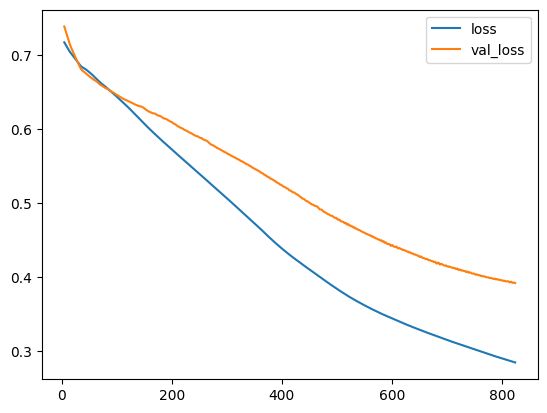

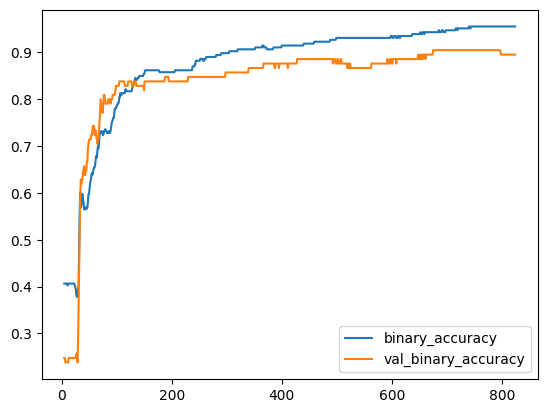

In [6]:
history_df = pd.DataFrame(history.history)

# Start the plot at epoch 5
history_df.loc[5:, ['loss', 'val_loss']].plot()
history_df.loc[5:, ['binary_accuracy', 'val_binary_accuracy']].plot()

print(f"Best Validation Loss: {history_df['val_loss'].min():0.4f}")
print(f"Best Validation Accuracy: {history_df['val_binary_accuracy'].max():0.4f}")